# Day 001 — Monthly clinic no-show rate by visit type

**Business question:** For a six-clinic primary care network, how has the monthly no-show rate changed over the last two years, and which visit types (and modalities) drive it?

**Definition:** no-show rate = no-shows ÷ (completed + no-shows). Cancellations are excluded.

All rows come from the seeded synthetic database in `shared/clinic.db`. They describe no real patients, providers, or clinics.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DB = Path("../../shared/clinic.db")
assert DB.exists(), f"Database not found: {DB.resolve()}"
conn = sqlite3.connect(DB)


## Network rate

In [2]:
overall = pd.read_sql("""
SELECT
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    SUM(CASE WHEN status = 'completed' THEN 1 ELSE 0 END) AS completed,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
""", conn)

cancelled = pd.read_sql("""
SELECT COUNT(*) AS cancelled_visits
FROM fact_appointment
WHERE status = 'cancelled'
""", conn)

by_year = pd.read_sql("""
SELECT
    strftime('%Y', visit_date) AS year,
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
GROUP BY 1
ORDER BY 1
""", conn)

display(overall)
display(cancelled)
display(by_year)


,eligible_visits,no_shows,completed,no_show_rate_pct
0,45090,7898,37192,17.5


,cancelled_visits
0,4448


,year,eligible_visits,no_shows,no_show_rate_pct
0,2024,22524,4068,18.1
1,2025,22566,3830,17.0


## By visit type, modality, and clinic

In [3]:
by_visit_type = pd.read_sql("""
SELECT
    visit_type,
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct,
    ROUND(AVG(lead_days), 1) AS avg_lead_days,
    ROUND(100.0 * AVG(CASE WHEN lead_days > 14 THEN 1.0 ELSE 0.0 END), 1) AS pct_lead_over_14_days
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
GROUP BY 1
ORDER BY no_show_rate_pct DESC
""", conn)

by_modality = pd.read_sql("""
SELECT
    modality,
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
GROUP BY 1
ORDER BY no_show_rate_pct DESC
""", conn)

c05_vs_peers = pd.read_sql("""
SELECT
    CASE WHEN clinic_id = 'C05' THEN 'C05 Brookfield' ELSE 'Peer clinics' END AS clinic_group,
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
GROUP BY 1
ORDER BY clinic_group
""", conn)

virtual_share = pd.read_sql("""
SELECT
    strftime('%Y', visit_date) AS year,
    COUNT(*) AS completed_visits,
    ROUND(
        100.0 * SUM(CASE WHEN modality IN ('video', 'audio') THEN 1 ELSE 0 END) / COUNT(*),
        1
    ) AS virtual_share_pct
FROM fact_appointment
WHERE status = 'completed'
GROUP BY 1
ORDER BY 1
""", conn)

display(by_visit_type)
display(by_modality)
display(c05_vs_peers)
display(virtual_share)


,visit_type,eligible_visits,no_shows,no_show_rate_pct,avg_lead_days,pct_lead_over_14_days
0,new_patient,4521,1088,24.1,16.2,54.0
1,preventive,8923,1853,20.8,12.4,36.3
2,chronic_followup,20458,3558,17.4,11.9,34.2
3,acute,11188,1399,12.5,3.9,6.9


,modality,eligible_visits,no_shows,no_show_rate_pct
0,in_person,32708,6618,20.2
1,video,8515,941,11.1
2,audio,3867,339,8.8


,clinic_group,eligible_visits,no_shows,no_show_rate_pct
0,C05 Brookfield,7504,1930,25.7
1,Peer clinics,37586,5968,15.9


,year,completed_visits,virtual_share_pct
0,2024,18456,27.9
1,2025,18736,31.8


## Monthly trend (with a 3-month moving average)

In [4]:
monthly = pd.read_sql("""
WITH monthly AS (
    SELECT
        strftime('%Y-%m', visit_date) AS year_month,
        COUNT(*) AS eligible_visits,
        SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
        1.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*) AS no_show_rate
    FROM fact_appointment
    WHERE status IN ('completed', 'no_show')
    GROUP BY 1
)
SELECT
    year_month,
    eligible_visits,
    no_shows,
    ROUND(100.0 * no_show_rate, 1) AS no_show_rate_pct,
    ROUND(100.0 * (no_show_rate - LAG(no_show_rate) OVER (ORDER BY year_month)), 1) AS mom_change_pp,
    ROUND(
        100.0 * AVG(no_show_rate) OVER (
            ORDER BY year_month
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ),
        1
    ) AS ma3_rate_pct
FROM monthly
ORDER BY year_month
""", conn)

monthly_by_type = pd.read_sql("""
SELECT
    strftime('%Y-%m', visit_date) AS year_month,
    visit_type,
    COUNT(*) AS eligible_visits,
    SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) AS no_shows,
    ROUND(100.0 * SUM(CASE WHEN status = 'no_show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS no_show_rate_pct
FROM fact_appointment
WHERE status IN ('completed', 'no_show')
GROUP BY 1, 2
ORDER BY 1, 2
""", conn)

monthly


,year_month,eligible_visits,no_shows,no_show_rate_pct,mom_change_pp,ma3_rate_pct
0,2024-01,2126,412,19.4,NaN,19.4
1,2024-02,1878,351,18.7,-0.7,19.0
2,2024-03,1949,359,18.4,-0.3,18.8
3,2024-04,2009,372,18.5,0.1,18.5
4,2024-05,2062,402,19.5,1.0,18.8
5,2024-06,1798,305,17.0,-2.5,18.3
6,2024-07,1546,278,18.0,1.0,18.1
7,2024-08,1611,264,16.4,-1.6,17.1
8,2024-09,1893,342,18.1,1.7,17.5
9,2024-10,2109,368,17.4,-0.6,17.3


## Chart

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


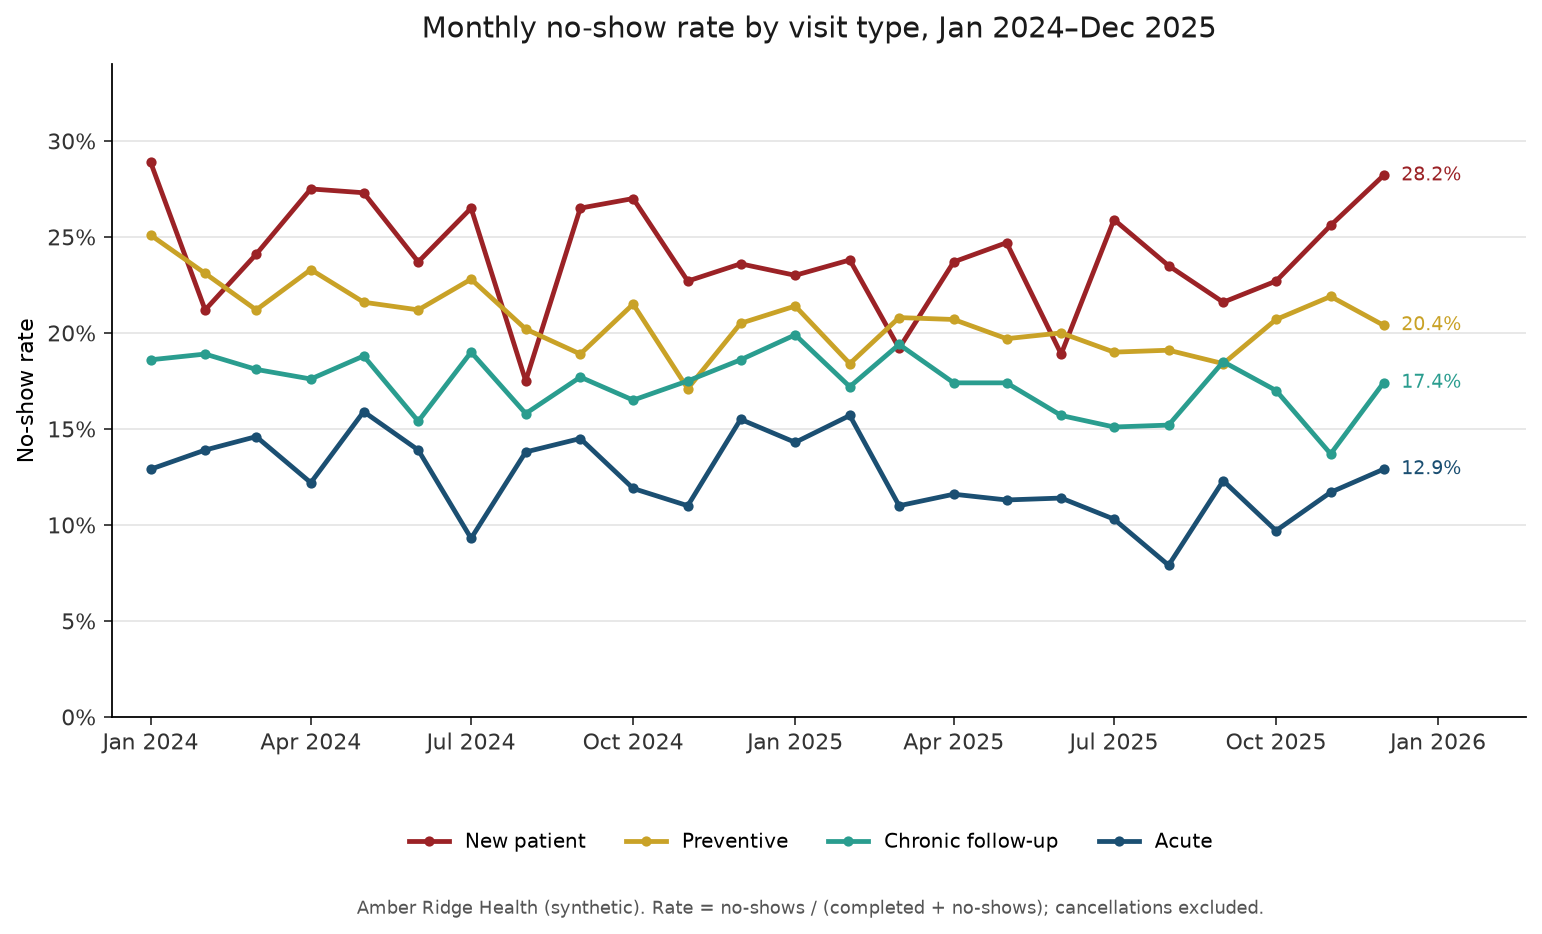

In [5]:
labels = {
    "acute": "Acute",
    "chronic_followup": "Chronic follow-up",
    "preventive": "Preventive",
    "new_patient": "New patient",
}
colors = {
    "acute": "#1b4f72",
    "chronic_followup": "#2a9d8f",
    "preventive": "#c9a227",
    "new_patient": "#9b2226",
}
order = ["new_patient", "preventive", "chronic_followup", "acute"]

plot_df = monthly_by_type.copy()
plot_df["month"] = pd.to_datetime(plot_df["year_month"] + "-01")

fig, ax = plt.subplots(figsize=(10.4, 6.0), dpi=160)
for vt in order:
    g = plot_df[plot_df["visit_type"] == vt].sort_values("month")
    ax.plot(
        g["month"],
        g["no_show_rate_pct"],
        color=colors[vt],
        linewidth=2.15,
        marker="o",
        markersize=3.6,
        label=labels[vt],
    )
    ax.annotate(
        f"{g['no_show_rate_pct'].iloc[-1]:.1f}%",
        xy=(g["month"].iloc[-1], g["no_show_rate_pct"].iloc[-1]),
        xytext=(8, 0),
        textcoords="offset points",
        color=colors[vt],
        fontsize=8.5,
        va="center",
        fontweight="medium",
    )

ax.set_title("Monthly no-show rate by visit type, Jan 2024–Dec 2025", fontsize=13, pad=12, color="#1a1a1a")
ax.set_ylabel("No-show rate")
ax.set_ylim(0, 34)
ax.set_xlim(pd.Timestamp("2023-12-10"), pd.Timestamp("2026-02-20"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"{v:.0f}%"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(colors="#333333")
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)

handles, labs = ax.get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.06), fontsize=9)
fig.text(
    0.5,
    0.015,
    "Amber Ridge Health (synthetic). Rate = no-shows / (completed + no-shows); cancellations excluded.",
    ha="center",
    fontsize=8,
    color="#555555",
)
fig.subplots_adjust(bottom=0.22, left=0.08, right=0.93, top=0.90)
fig.savefig("chart.png", facecolor="white")
plt.show()


## Takeaway

- New-patient visits no-show at **24.1%**, nearly twice the **12.5%** acute rate, and 54% of them are booked more than 14 days out.
- In-person visits no-show at **20.2%**, versus **11.1%** video and **8.8%** audio-only. Virtual share of completed visits rose from 27.9% (2024) to 31.8% (2025).
- Brookfield (C05) is the operations outlier: **25.7%** versus **15.9%** at peer clinics.

A clinic manager should put reminder outreach on long-lead new-patient and preventive visits, offer virtual chronic follow-up when the next in-person slot is far out, and review Brookfield before changing network-wide policy.


In [6]:
conn.close()